# 01 - Data acquisition, cleaning and EDA
**Heart Disease UCI** - all four hospitals (Cleveland, Hungary, Switzerland, VA Long Beach), 920 rows.

Most course solutions use only the 303-row Cleveland file. Combining all four sites triples the data
but brings real-world problems: heavy, *site-dependent* missingness and sentinel zeros. This notebook
documents how those are handled. The same code lives in `src/cardiorisk/data.py` and `eda.py`, so the
notebook and the pipeline cannot drift apart.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("CARDIORISK_ROOT", str(ROOT))
print("project root:", ROOT)

project root: /home/claude/heart-disease-mlops


## 1. Acquire
`scripts/download_data.py` downloads the UCI zip (or uses a local copy with `--zip`), writes SHA-256 checksums and builds the cleaned CSV.

In [2]:
import subprocess
print(subprocess.run([sys.executable, str(ROOT / "scripts/download_data.py"), "--skip-if-present"],
                     capture_output=True, text=True, cwd=ROOT).stdout)

Raw files already present - skipping download
a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8  processed.cleveland.data
d1ad108f785768cd3d7e82dc522e6f5a61eea93cccfb3a46ee8076f73fc3d796  processed.hungarian.data
834a405ccf5b66ab4056bb77794adc8df0b7125186454c0a1d002d33c6c3b314  processed.switzerland.data
e7c93d8d0d2acdadfa4c5e8de768e2191e7f618b952e29623f1f0d5949ff6b8f  processed.va.data
ec7ed5aa4ed8321097808f47b836301c2a0c36f3bb09c40b8b43b622363e6b61  heart-disease.names
Clean dataset: 918 rows, positive rate 0.553



In [3]:
import pandas as pd
from cardiorisk import config
from cardiorisk.data import load_raw, clean, missing_report
raw = load_raw()
print(raw.shape)
raw.head()

(920, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,source
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,cleveland
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,cleveland
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,cleveland
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,cleveland
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,cleveland


## 2. Clean
* `?` -> NaN when reading
* target `num` (0-4) -> binary `target = num > 0`
* `chol == 0` and `trestbps == 0` are impossible -> NaN (all 123 Swiss rows have chol = 0)
* out-of-range numerics and undocumented category codes -> NaN
* exact duplicates dropped (2 rows)

Rows are **not** dropped for missing features: imputation happens inside the model pipeline, so serving applies identical logic.

In [4]:
df = clean(raw)
print("rows:", len(raw), "->", len(df))
print("positive rate:", round(df.target.mean(), 3))
df.describe().T.round(2)

rows: 920 -> 918
positive rate: 0.553


,count,mean,std,min,25%,50%,75%,max
age,918.0,53.51,9.43,28.0,47.0,54.0,60.0,77.0
trestbps,858.0,132.29,18.53,80.0,120.0,130.0,140.0,200.0
chol,717.0,246.87,58.56,85.0,210.0,240.0,277.0,603.0
thalach,863.0,137.54,25.94,60.0,120.0,140.0,157.0,202.0
oldpeak,856.0,0.88,1.09,-2.6,0.0,0.5,1.5,6.2
sex,918.0,0.79,0.41,0.0,1.0,1.0,1.0,1.0
cp,918.0,3.25,0.93,1.0,3.0,4.0,4.0,4.0
fbs,828.0,0.17,0.37,0.0,0.0,0.0,0.0,1.0
restecg,916.0,0.60,0.81,0.0,0.0,0.0,1.0,2.0
exang,863.0,0.39,0.49,0.0,0.0,0.0,1.0,1.0


In [5]:
missing_report(df)

,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal
source,,,,,,,,,,,,,
cleveland,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.3,0.7
hungarian,0.0,0.3,7.5,0.3,0.0,0.0,0.0,2.7,0.3,0.3,64.5,99.0,90.4
switzerland,0.0,1.6,100.0,0.8,4.9,0.0,0.0,61.0,0.8,0.8,13.8,95.9,42.3
va_long_beach,0.0,28.6,28.1,26.6,28.1,0.0,0.0,3.5,0.0,26.6,50.8,99.0,82.9
ALL,0.0,6.5,21.9,6.0,6.8,0.0,0.0,9.8,0.2,6.0,33.4,66.3,52.7


## 3. Visual EDA

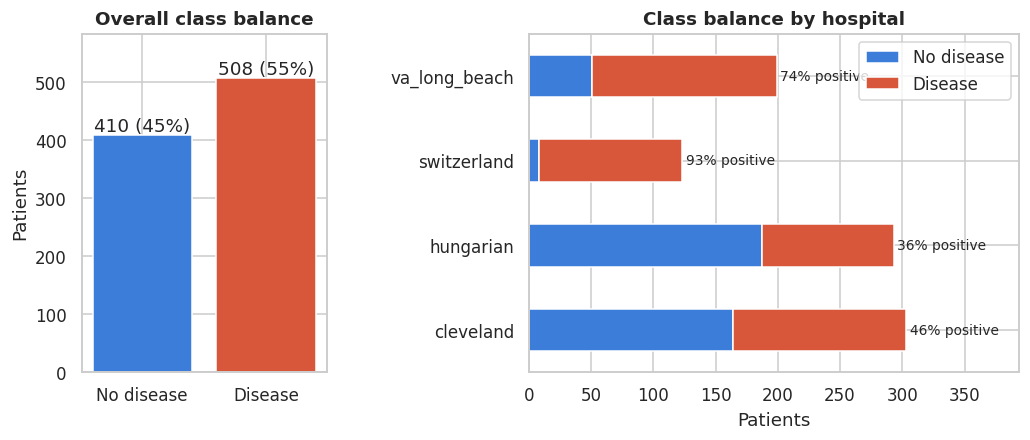

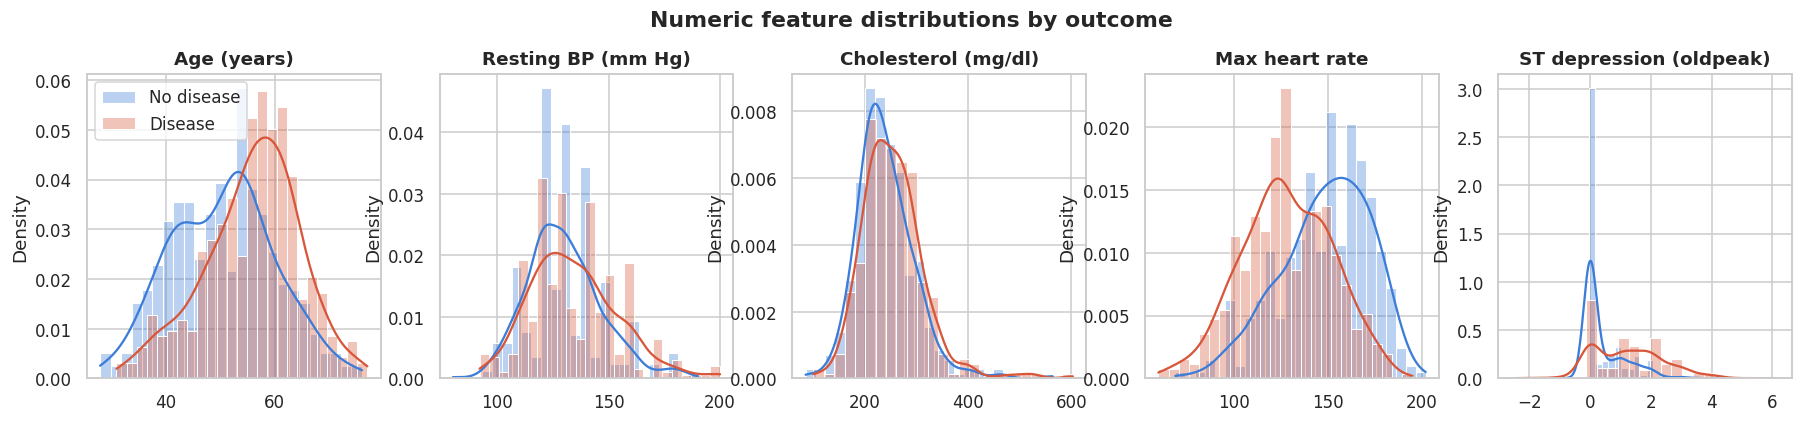

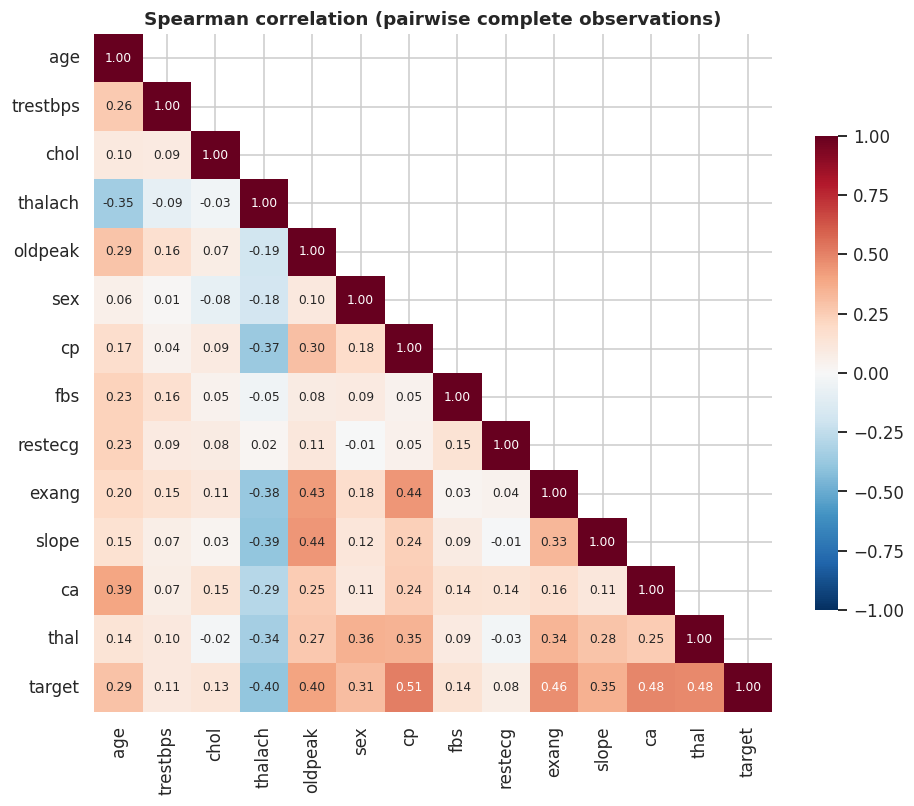

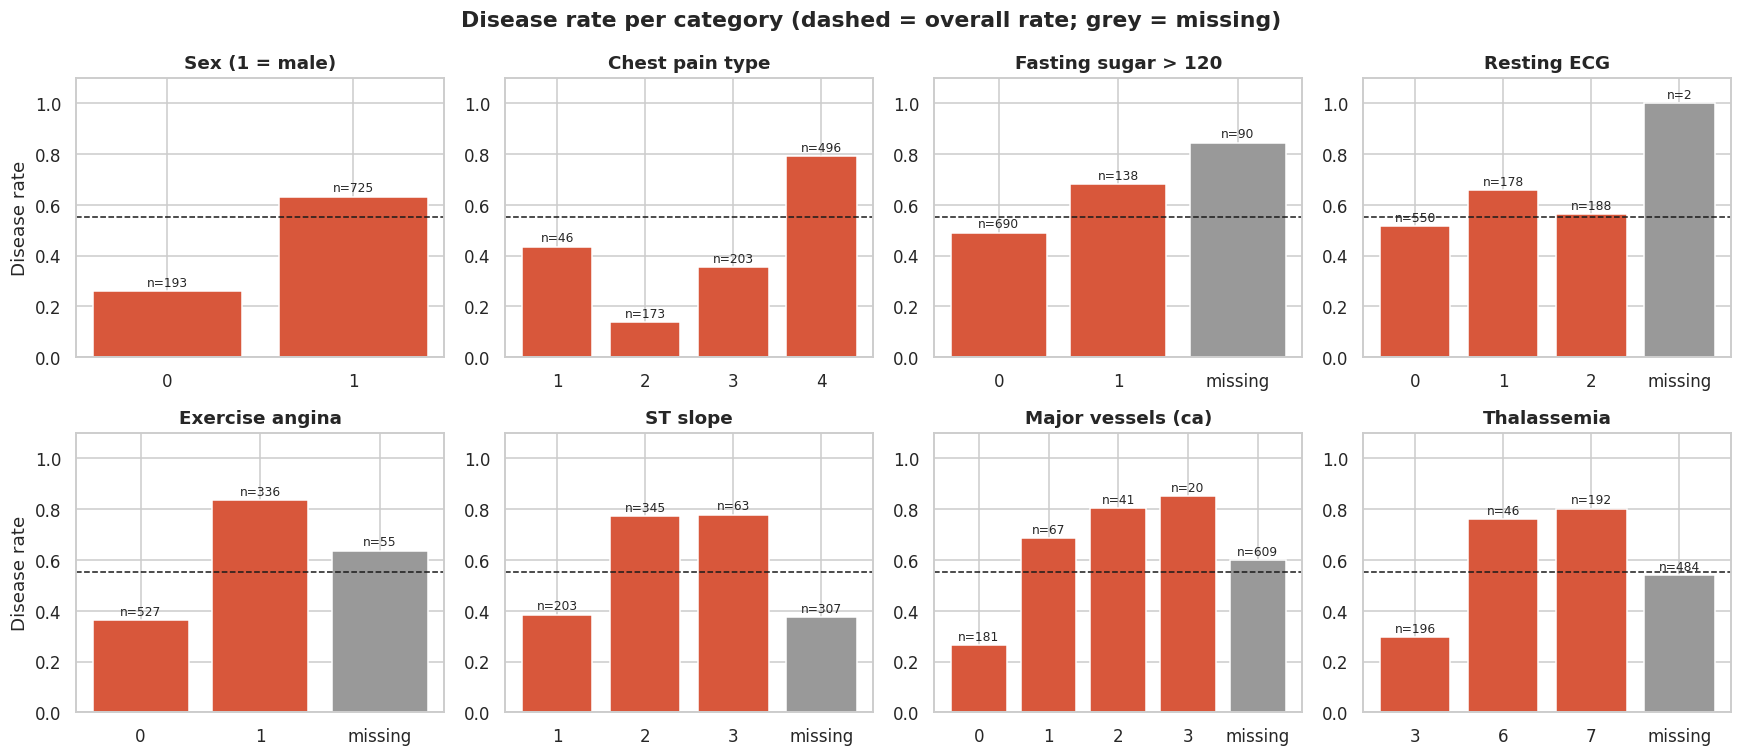

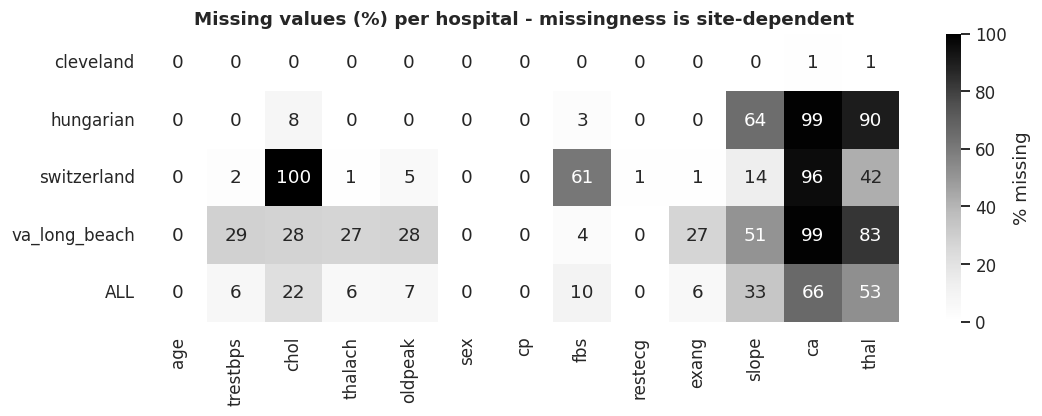

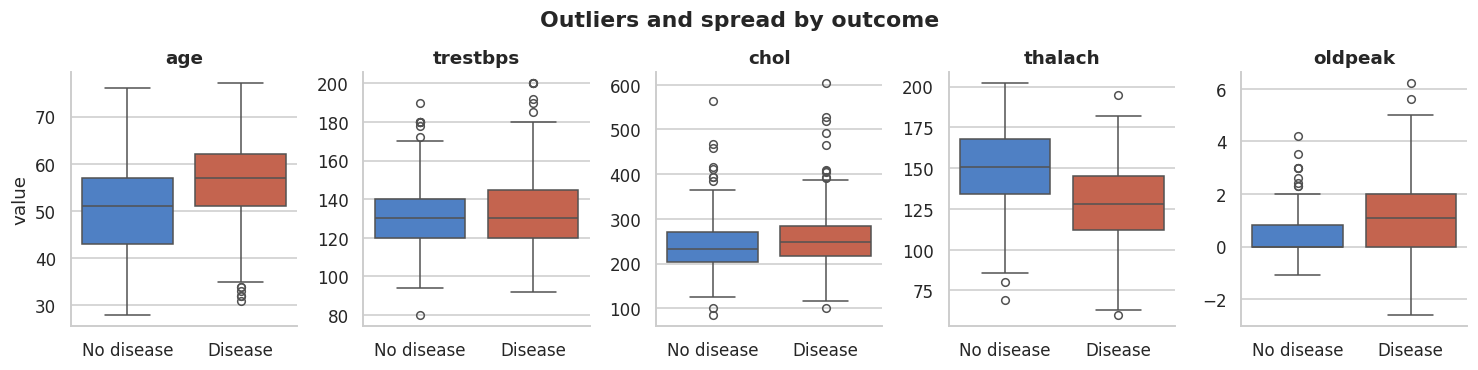

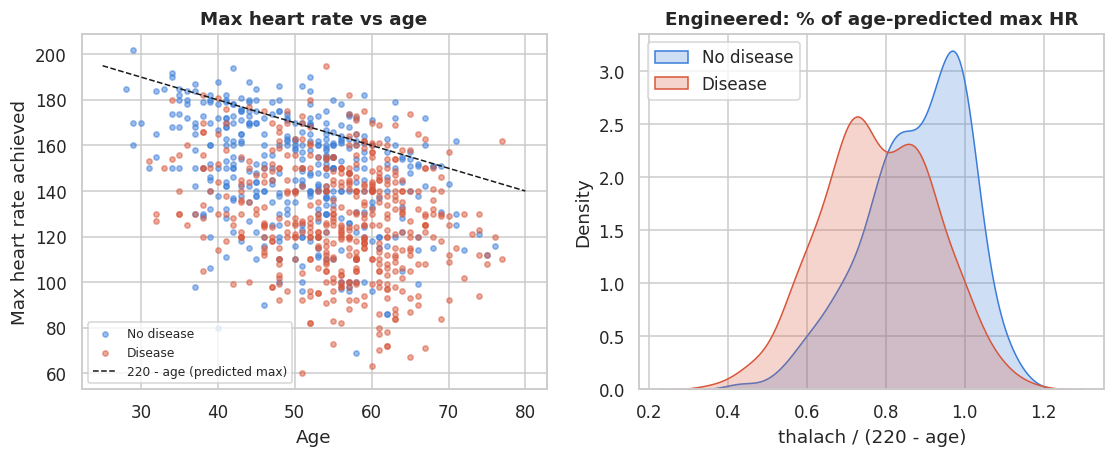

In [6]:
from IPython.display import Image, display
from cardiorisk.eda import run_eda
summary = run_eda()
for f in summary["figures"]:
    display(Image(filename=str(config.FIGURES_DIR / f)))

In [7]:
pd.Series(summary["top_abs_spearman_with_target"], name="|spearman| with target")

cp         0.512
ca         0.484
thal       0.484
exang      0.462
oldpeak    0.402
thalach    0.398
Name: |spearman| with target, dtype: float64

## 4. Findings that shaped the modelling
1. **Class balance** is fine overall (55% positive) but differs strongly by hospital (36% Hungary vs 93% Switzerland) -> stratify the split on *site x target*.
2. **Missingness is a proxy for the hospital**: `ca` is 99% missing outside Cleveland, `chol` 100% missing in Switzerland. Missing-value *indicators* would let a model learn "which hospital" rather than physiology, so they are off by default and tested as an ablation in training.
3. Strongest signals: chest-pain type 4 (asymptomatic), exercise angina, ST depression (`oldpeak`), max heart rate, sex. `thalach` falls with age, which motivates the engineered feature **`hr_reserve_pct = thalach / (220 - age)`**.
4. `chol` and `trestbps` have long right tails -> **RobustScaler** instead of StandardScaler.
5. Categorical codes are nominal (e.g. `cp` 1-4, `thal` 3/6/7) -> one-hot encoding, with "missing" as its own level for `ca`/`thal`/`slope` (often simply not measured).